# Stage 7 — Interpretability & Error Diagnostics

Numbers tell us the model works. This notebook tells us **why** it works and **where** it fails. That's what turns a working script into research.

## What we look at
1. **SHAP feature importance** for H+1 and H+7 — are the model's drivers physically plausible?
2. **Error maps** — where in the box are residuals worst? Coastal? Coastal-shelf edge? Offshore?
3. **Error by season** — does winter error dominate as the coverage atlas (Gate 2) predicted?
4. **Residual structure** — pred-vs-actual and residual-vs-prediction scatter, looking for trends that suggest missing features.

## What "physically plausible" means here
PLAN.md is explicit: at short horizons we expect **recent CHL lags + SST** to dominate. If `doy_sin/cos` alone dominate, the model is doing little more than learning the annual cycle — that's a flag, not a win. SHAP should make this obvious.

## Outputs
- `figs/07_shap_h1.png`, `figs/07_shap_h7.png` — SHAP summary plots
- `figs/07_shap_bar_h1_h7.png` — mean absolute SHAP comparison
- `figs/07_error_map_h3.png` — per-pixel mean absolute error
- `figs/07_error_by_month.png` — seasonal error distribution
- `figs/07_residual_diagnostics_h3.png` — pred vs actual + residuals vs pred

## 7.0 — Load data, manifest, models

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import xgboost as xgb

PROC_DIR  = Path("data/processed")
MODEL_DIR = Path("models")
FIG_DIR   = Path("figs"); FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(PROC_DIR / "supervised_sample.parquet").sort_values("time").reset_index(drop=True)
with open(PROC_DIR / "feature_manifest.json") as f:
    manifest = json.load(f)

FEATURE_COLS = manifest["feature_cols"]
HORIZONS     = manifest["horizons"]

# same chronological cuts as Notebook 6
cut_train = df["time"].quantile(0.70)
cut_val   = df["time"].quantile(0.85)
test = df[df.time > cut_val].copy()

# Load models
models = {}
for h in HORIZONS:
    m = xgb.XGBRegressor()
    m.load_model(MODEL_DIR / f"xgb_h{h}.json")
    models[h] = m

print(f"Loaded {len(models)} models for horizons {list(models.keys())}")
print(f"Test rows: {len(test):,}")
print(f"Features  : {len(FEATURE_COLS)}")

Loaded 7 models for horizons [1, 2, 3, 4, 5, 6, 7]
Test rows: 17,899
Features  : 15


## 7.1 — SHAP feature importance (H+1 and H+7)

Tree-aware SHAP is fast: a few seconds on 5000 sample rows for an XGBoost model.

We pick the **two endpoints** of the horizon range. The story at H+1 (short, persistence-dominated) should be different from H+7 (longer, where lags lose their grip and other features should rise). If both look identical, the model isn't really using horizon-specific information.

In [2]:
import shap

SHAP_N = 5000
sample_for_shap = test[FEATURE_COLS].sample(min(SHAP_N, len(test)), random_state=0)

shap_values = {}
for h in [1, 7]:
    explainer = shap.TreeExplainer(models[h])
    sv = explainer.shap_values(sample_for_shap)
    shap_values[h] = sv
    print(f"H+{h}: SHAP computed for {sv.shape[0]} rows × {sv.shape[1]} features")

H+1: SHAP computed for 5000 rows × 15 features
H+7: SHAP computed for 5000 rows × 15 features


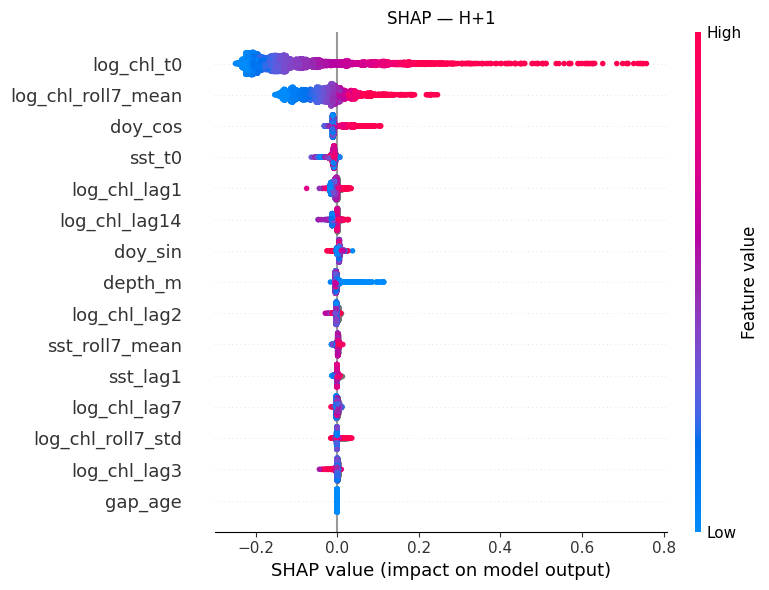

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values[1], sample_for_shap, show=False, plot_size=None)
plt.title("SHAP — H+1")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_shap_h1.png", dpi=150, bbox_inches="tight")
plt.show()

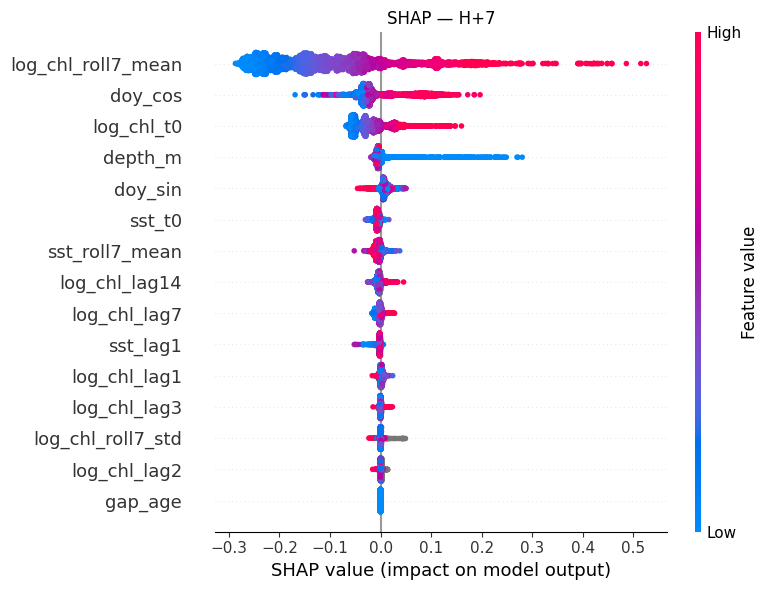

In [4]:
plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values[7], sample_for_shap, show=False, plot_size=None)
plt.title("SHAP — H+7")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_shap_h7.png", dpi=150, bbox_inches="tight")
plt.show()

### Mean absolute SHAP — direct comparison

The summary plots are dense. A bar chart of mean |SHAP| per feature, side-by-side for H+1 and H+7, makes the *change in importance ranking* with horizon legible at a glance.

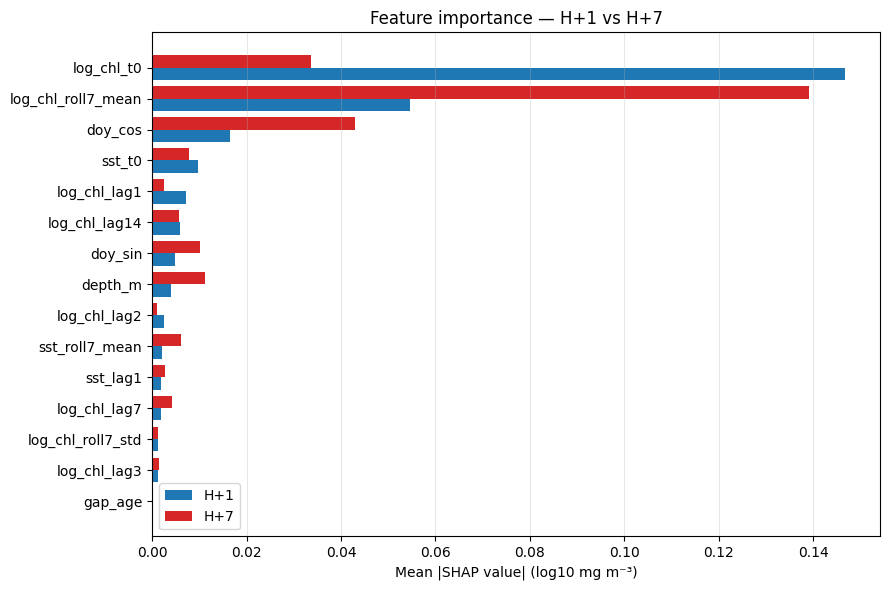


Top 5 features at each horizon:

H+1:
  log_chl_t0                0.1468
  log_chl_roll7_mean        0.0547
  doy_cos                   0.0164
  sst_t0                    0.0098
  log_chl_lag1              0.0071

H+7:
  log_chl_roll7_mean        0.1391
  doy_cos                   0.0429
  log_chl_t0                0.0336
  depth_m                   0.0111
  doy_sin                   0.0102


In [5]:
shap_summary = pd.DataFrame({
    "feature": FEATURE_COLS,
    "H+1": np.abs(shap_values[1]).mean(axis=0),
    "H+7": np.abs(shap_values[7]).mean(axis=0),
}).sort_values("H+1", ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(shap_summary))
ax.barh(y - 0.2, shap_summary["H+1"], height=0.4, label="H+1", color="#1f77b4")
ax.barh(y + 0.2, shap_summary["H+7"], height=0.4, label="H+7", color="#d62728")
ax.set_yticks(y); ax.set_yticklabels(shap_summary["feature"])
ax.set_xlabel("Mean |SHAP value| (log10 mg m⁻³)")
ax.set_title("Feature importance — H+1 vs H+7")
ax.legend(); ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_shap_bar_h1_h7.png", dpi=150)
plt.show()

print("\nTop 5 features at each horizon:")
for h in [1, 7]:
    top = shap_summary.sort_values(f"H+{h}", ascending=False).head(5)
    print(f"\nH+{h}:")
    for _, r in top.iterrows():
        print(f"  {r['feature']:25s} {r[f'H+{h}']:.4f}")

## 7.2 — Predict on test & compute residuals (H+3 reference horizon)

We pick **H+3** for the error diagnostics: short enough to have plenty of valid targets, long enough that persistence is no longer dominating. This is the horizon where the model's contribution is most clearly visible.

Residual = `predicted − actual` (both in log10 space). Negative residual = model underpredicts (real CHL higher than predicted).

In [6]:
REF_H = 3
tgt = f"target_h{REF_H}"

mask = test[tgt].notna()
X = test.loc[mask, FEATURE_COLS]
y = test.loc[mask, tgt].values
pred = models[REF_H].predict(X)

diag = test.loc[mask, ["time", "latitude", "longitude"]].copy()
diag["y"]    = y
diag["pred"] = pred
diag["residual"] = pred - y
diag["abs_residual"] = np.abs(diag["residual"])
diag["month"] = diag["time"].dt.month

print(f"Reference horizon : H+{REF_H}")
print(f"Test rows scored  : {len(diag):,}")
print(f"Mean |residual|   : {diag.abs_residual.mean():.4f}")
print(f"Bias              : {diag.residual.mean():+.4f}  (positive = model over-predicts)")

Reference horizon : H+3
Test rows scored  : 11,411
Mean |residual|   : 0.0716
Bias              : +0.0104  (positive = model over-predicts)


## 7.3 — Per-pixel error map

Aggregate test errors by pixel. A clear coast-vs-offshore or shelf-edge pattern would point at missing features (wind / MLD / current advection) — they're coming in Stage 8.

Few test rows per pixel = unstable per-pixel mean. We require ≥ 3 test observations to colour a pixel; pixels with fewer stay grey.

Pixels with ≥ 3 test obs: 100 / 10,116


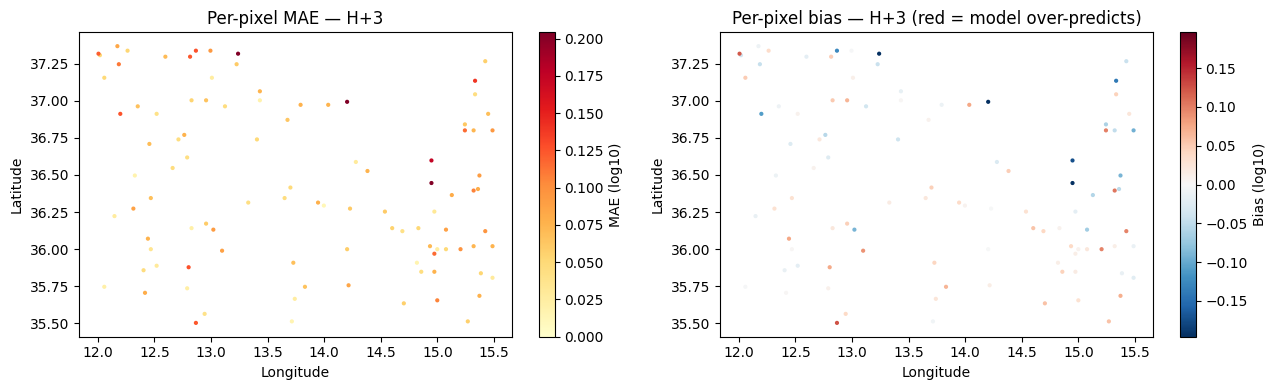

In [7]:
per_pixel = (diag.groupby(["latitude", "longitude"])
                  .agg(mae=("abs_residual", "mean"),
                       bias=("residual", "mean"),
                       n=("abs_residual", "size"))
                  .reset_index())
per_pixel.loc[per_pixel["n"] < 3, ["mae", "bias"]] = np.nan
print(f"Pixels with ≥ 3 test obs: {per_pixel['n'].ge(3).sum():,} / {len(per_pixel):,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
vmax = per_pixel["mae"].quantile(0.98)
im0 = axes[0].scatter(per_pixel.longitude, per_pixel.latitude,
                      c=per_pixel.mae, cmap="YlOrRd", s=4, vmin=0, vmax=vmax)
axes[0].set_title(f"Per-pixel MAE — H+{REF_H}")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
plt.colorbar(im0, ax=axes[0], label="MAE (log10)")

bias_lim = np.nanmax(np.abs(per_pixel["bias"].quantile([0.02, 0.98]).values))
im1 = axes[1].scatter(per_pixel.longitude, per_pixel.latitude,
                      c=per_pixel.bias, cmap="RdBu_r", s=4,
                      vmin=-bias_lim, vmax=bias_lim)
axes[1].set_title(f"Per-pixel bias — H+{REF_H} (red = model over-predicts)")
axes[1].set_xlabel("Longitude"); axes[1].set_ylabel("Latitude")
plt.colorbar(im1, ax=axes[1], label="Bias (log10)")

plt.tight_layout()
plt.savefig(FIG_DIR / "07_error_map_h3.png", dpi=150)
plt.show()

## 7.4 — Error by season

Boxplot of absolute residual by month. **PLAN.md prediction (Gate 2):** winter error should be worst, because winter has the lowest valid-pixel coverage *and* the most dynamic bloom events. The coverage atlas told us DJF coverage is 40–49%, the lowest of the year. If the model's error tracks that pattern, the story is consistent.

C:\Users\alang\AppData\Local\Temp\ipykernel_23852\1766073420.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(by_month, labels=MONTH_LABELS, showfliers=False, patch_artist=True)


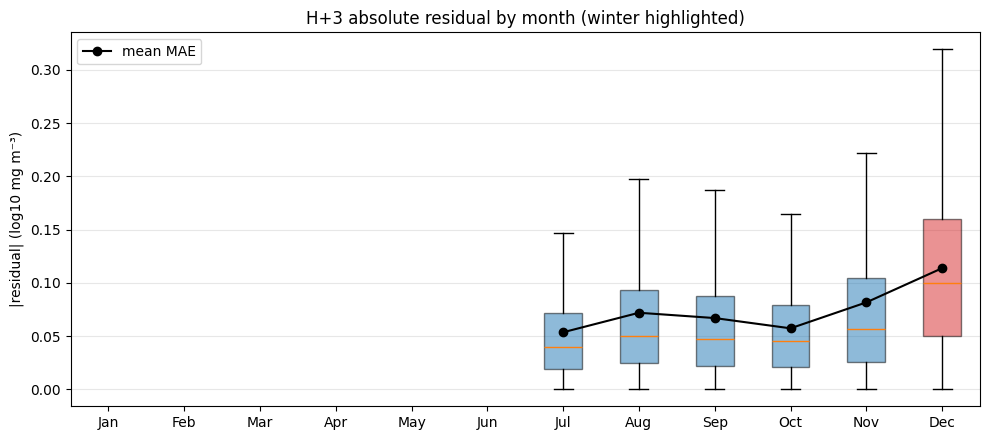


Mean MAE by month:
month
7     0.0535
8     0.0719
9     0.0669
10    0.0572
11    0.0816
12    0.1137

Winter (DJF) mean MAE : 0.1137
Summer (JJA) mean MAE : 0.0627
Winter / Summer ratio : 1.81x


In [8]:
import matplotlib.pyplot as plt

MONTH_LABELS = ["Jan","Feb","Mar","Apr","May","Jun",
                "Jul","Aug","Sep","Oct","Nov","Dec"]

# group residuals by month into a list-of-arrays for boxplot
by_month = [diag.loc[diag.month == m, "abs_residual"].values for m in range(1, 13)]

monthly_mae = diag.groupby("month")["abs_residual"].mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
bp = ax.boxplot(by_month, labels=MONTH_LABELS, showfliers=False, patch_artist=True)
for patch, m in zip(bp["boxes"], range(1, 13)):
    patch.set_facecolor("#d62728" if m in (12, 1, 2) else "#1f77b4")
    patch.set_alpha(0.5)
ax.plot(range(1, 13), monthly_mae.reindex(range(1, 13)).values,
        marker="o", color="k", label="mean MAE")
ax.set_ylabel("|residual| (log10 mg m⁻³)")
ax.set_title(f"H+{REF_H} absolute residual by month (winter highlighted)")
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_error_by_month.png", dpi=150)
plt.show()

print("\nMean MAE by month:")
print((monthly_mae * 1).round(4).to_string())
winter_months = [12, 1, 2]
winter_mae = monthly_mae.reindex(winter_months).mean()
summer_mae = monthly_mae.reindex([6, 7, 8]).mean()
print(f"\nWinter (DJF) mean MAE : {winter_mae:.4f}")
print(f"Summer (JJA) mean MAE : {summer_mae:.4f}")
print(f"Winter / Summer ratio : {winter_mae/summer_mae:.2f}x")

## 7.5 — Residual diagnostics

Two scatter plots:
- **Pred vs actual** — points should lie close to the 1:1 line. Compression toward the mean (a "shrinkage") is normal for tree models on noisy data.
- **Residual vs predicted** — looking for *structure*: a fan shape is heteroscedasticity (OK, common); a slope means the model has a systematic bias proportional to prediction (missing feature).

We thin to 5000 random points for legibility.

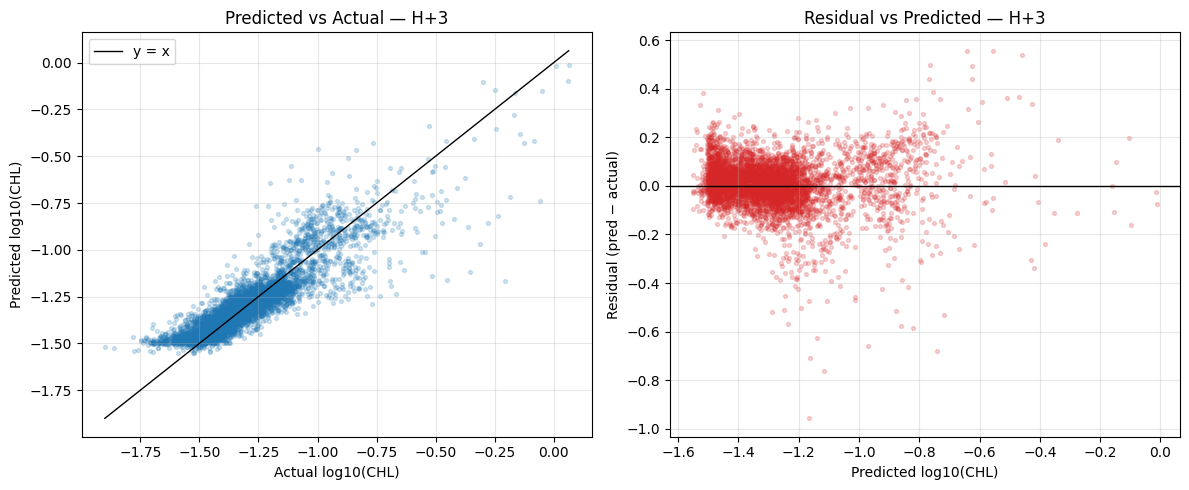

Pearson(residual, predicted) = -0.042
  |.| < 0.10 → no obvious structural bias
  |.| > 0.30 → suggests a missing feature explaining the trend


In [9]:
sub = diag.sample(min(5000, len(diag)), random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# pred vs actual
axes[0].scatter(sub.y, sub.pred, alpha=0.2, s=8, color="#1f77b4")
lo = min(sub.y.min(), sub.pred.min())
hi = max(sub.y.max(), sub.pred.max())
axes[0].plot([lo, hi], [lo, hi], "k-", linewidth=1, label="y = x")
axes[0].set_xlabel("Actual log10(CHL)")
axes[0].set_ylabel("Predicted log10(CHL)")
axes[0].set_title(f"Predicted vs Actual — H+{REF_H}")
axes[0].legend(); axes[0].grid(alpha=0.3)

# residual vs predicted
axes[1].scatter(sub.pred, sub.residual, alpha=0.2, s=8, color="#d62728")
axes[1].axhline(0, color="k", linewidth=1)
axes[1].set_xlabel("Predicted log10(CHL)")
axes[1].set_ylabel("Residual (pred − actual)")
axes[1].set_title(f"Residual vs Predicted — H+{REF_H}")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "07_residual_diagnostics_h3.png", dpi=150)
plt.show()

# correlation of residual with predicted — close to 0 = no structural bias
corr = np.corrcoef(sub.pred, sub.residual)[0, 1]
print(f"Pearson(residual, predicted) = {corr:+.3f}")
print("  |.| < 0.10 → no obvious structural bias")
print("  |.| > 0.30 → suggests a missing feature explaining the trend")

---
## Validation Gate 7

Three checks. They're qualitative — read off the plots and confirm. The gate cell automates the parts that can be automated.

1. **Top SHAP features are physically plausible.** At H+1, recent CHL lags (lag1/lag2/roll7) should dominate, with SST appearing as a secondary contributor. If `doy_sin`/`doy_cos` alone dominate, the model is just learning the seasonal cycle — flag it.
2. **Winter error ≥ summer error.** Consistent with the Gate 2 coverage atlas (winter is the cloudiest, most bloom-dynamic season).
3. **Residuals show no strong trend vs predicted value.** Heteroscedasticity (fan shape) is fine; a *slope* suggests a missing feature.

In [10]:
results = {}

# 1) plausibility: top feature at H+1 must be a CHL-history feature or SST
top_h1 = shap_summary.sort_values("H+1", ascending=False).iloc[0]["feature"]
plausible_drivers = {"log_chl_t0", "log_chl_lag1", "log_chl_lag2", "log_chl_lag3",
                     "log_chl_lag7", "log_chl_lag14",
                     "log_chl_roll7_mean", "log_chl_roll7_std",
                     "sst_t0", "sst_lag1", "sst_roll7_mean"}
results["H+1 top SHAP feature is CHL/SST (not doy alone)"] = top_h1 in plausible_drivers

# 2) winter error ≥ summer error
results["winter MAE ≥ summer MAE"] = winter_mae >= summer_mae

# 3) residual-vs-predicted has no strong structural slope
results["|corr(residual, predicted)| < 0.30"] = abs(corr) < 0.30

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(f"\nTop H+1 SHAP feature       : {top_h1}")
print(f"Winter / summer MAE ratio  : {winter_mae/summer_mae:.2f}x")
print(f"corr(residual, predicted)  : {corr:+.3f}")

if all(results.values()):
    print("\nGate 7 PASSED — interpretability is consistent with the science.")
    print("Proceed to 08-Full-Covariates.")
else:
    print("\nGate 7 FAILED — read the plots before continuing.")
    print("  • doy_sin dominates → model has not learned dynamics, only the seasonal cycle")
    print("  • winter MAE < summer MAE → unexpected; may indicate summer over-fitting")
    print("  • strong residual slope → a major driver is missing; Stage 8 should add it")

PASS  H+1 top SHAP feature is CHL/SST (not doy alone)
PASS  winter MAE ≥ summer MAE
PASS  |corr(residual, predicted)| < 0.30

Top H+1 SHAP feature       : log_chl_t0
Winter / summer MAE ratio  : 1.81x
corr(residual, predicted)  : -0.042

Gate 7 PASSED — interpretability is consistent with the science.
Proceed to 08-Full-Covariates.


---
## What to take into Notebook 8

Read the per-pixel error map carefully. Common patterns and what they mean:
- **Coastal MAE high, offshore low** → missing wind/upwelling. Stage 8 ERA5 + ASCAT will help.
- **Shelf-edge MAE high, deep MAE low** → missing currents/MLD. Stage 8 CMEMS PHY will help.
- **Uniformly high MAE** → noise floor, not a missing-feature problem. Look at sampling / data quality before adding features.

These are the hypotheses that **group ablation** in Stage 8 will test rigorously.

## Next: `08-Full-Covariates.ipynb`

Brings in the full predictor roster (wind, waves, salinity, currents, SSH, MLD, optics), handles correlated predictors via group-level importance and ablation, and re-runs Stage 6 with the expanded stack.

---
## 7.7 — Full-grid prediction (bonus: every water pixel, no interpolation)

The 7.6 viewer interpolates from ~110 sample points per day. Here we go the other way: rebuild the **full feature stack on the entire grid** for the test period, predict every pixel, every horizon, every day, and view the dense maps directly.

**What this costs.** One-off precompute of ~3-5 minutes. ~1 GB of RAM for the cached prediction arrays. After that the player is instant — pure `pcolormesh` reads from xarray DataArrays.

**What you can actually see on the dense maps:**
- The fine-scale spatial structure the model produces under cloud (XGBoost predicts in gap pixels where actual is NaN — that's the value proposition of native NaN handling).
- Where the prediction is *smoother* than the actual (model regularising over noise) and where it tracks fine structure (genuine signal).
- True per-pixel error fields that aren't biased by the sample's irregular geometry.

**Why we didn't do this in 7.6.** Two views serve different roles. 7.6 is the honest "scattered observations" view — what you actually have. 7.7 is the "interpolation by model" view — what the model gives you everywhere. Compare them: the model interpolation tends to look more physically reasonable than the linear-griddata interpolation in 7.6, which is itself a finding.

In [12]:
# ---- 7.7a — rebuild full feature stack over the test period (no sampling) ----

import time as pytime
t0 = pytime.time()
import xarray as xr

CHL_PATH   = Path("data/raw/chl_malta_2021_2023.nc")
SST_PATH   = Path("data/raw/sst_malta_2021_2023.nc")
BATHY_PATH = Path("data/raw/bathy_malta.nc")

chl_ds   = xr.open_dataset(CHL_PATH)
sst_ds   = xr.open_dataset(SST_PATH)
bathy_ds = xr.open_dataset(BATHY_PATH)

chl = chl_ds["CHL"]
sst = sst_ds["analysed_sst"]
if float(sst.isel(time=0).max()) > 200:
    sst = sst - 273.15
elev_var = next(v for v in bathy_ds.data_vars if v in ("z", "elevation", "bed_elevation"))
elev = bathy_ds[elev_var]
depth = -elev.where(elev < 0, 0)
log_chl = np.log10(chl).rename("log_chl")

# Align predictors onto CHL grid
sst_on_chl   = sst.interp(latitude=chl.latitude, longitude=chl.longitude)
depth_on_chl = depth.interp(latitude=chl.latitude, longitude=chl.longitude)
sst_on_chl   = sst_on_chl.reindex(time=chl.time, method="nearest",
                                  tolerance=np.timedelta64(1, "D"))

# We need ~max(LAGS)=14 extra days before TEST_START to populate lag features.
TEST_START = pd.Timestamp(test["time"].min())
LOOKBACK   = pd.Timedelta(days=20)
slice_start = TEST_START - LOOKBACK
log_chl_slc = log_chl.sel(time=slice(slice_start, None))
sst_slc     = sst_on_chl.sel(time=slice(slice_start, None))

# Build features (same definitions as Notebook 4)
feat = xr.Dataset()
feat["log_chl_t0"] = log_chl_slc
for lag in [1, 2, 3, 7, 14]:
    feat[f"log_chl_lag{lag}"] = log_chl_slc.shift(time=lag)
feat["log_chl_roll7_mean"] = log_chl_slc.rolling(time=7, min_periods=1).mean()
feat["log_chl_roll7_std"]  = log_chl_slc.rolling(time=7, min_periods=2).std()
feat["sst_t0"]         = sst_slc
feat["sst_lag1"]       = sst_slc.shift(time=1)
feat["sst_roll7_mean"] = sst_slc.rolling(time=7, min_periods=1).mean()
feat["depth_m"] = depth_on_chl.broadcast_like(log_chl_slc)
doy = log_chl_slc.time.dt.dayofyear
feat["doy_sin"] = np.sin(2*np.pi*doy/365.25).broadcast_like(log_chl_slc)
feat["doy_cos"] = np.cos(2*np.pi*doy/365.25).broadcast_like(log_chl_slc)

# gap_age — vectorised loop over time
valid = (~np.isnan(log_chl_slc.values)).astype(np.int32)
gap_age_arr = np.empty_like(valid)
gap_age_arr[0] = 0
for tt in range(1, valid.shape[0]):
    gap_age_arr[tt] = np.where(valid[tt], 0, gap_age_arr[tt-1] + 1)
feat["gap_age"] = xr.DataArray(gap_age_arr, dims=log_chl_slc.dims, coords=log_chl_slc.coords)

# Restrict to the actual test period
feat_test = feat.sel(time=slice(TEST_START, None))
print(f"Feature cube: {dict(feat_test.sizes)}  ({pytime.time()-t0:.1f}s)")

c:\GIT\mcast.pages.ai.v2\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Feature cube: {'latitude': 198, 'longitude': 272, 'time': 162}  (5.5s)


In [13]:
# ---- 7.7b — predict every pixel × day × horizon ----

t0 = pytime.time()

# Flatten to 2D (n_rows, n_features) for xgboost
n_time, n_lat, n_lon = feat_test.sizes["time"], feat_test.sizes["latitude"], feat_test.sizes["longitude"]
n_rows = n_time * n_lat * n_lon

# Build the feature matrix in the column order the model expects
X_flat = np.stack([feat_test[c].values.reshape(n_rows) for c in FEATURE_COLS], axis=1)
print(f"X shape: {X_flat.shape}  ({X_flat.nbytes/1e6:.0f} MB)  ({pytime.time()-t0:.1f}s)")

# Predict per horizon, reshape back to (time, lat, lon)
pred_grids = {}
for h in HORIZONS:
    tt0 = pytime.time()
    p = models[h].predict(X_flat).astype(np.float32)
    pred_grids[h] = xr.DataArray(
        p.reshape(n_time, n_lat, n_lon),
        dims=("time", "latitude", "longitude"),
        coords={"time": feat_test.time, "latitude": feat_test.latitude, "longitude": feat_test.longitude},
        name=f"pred_h{h}",
    )
    print(f"  H+{h} predicted  ({pytime.time()-tt0:.1f}s)")

# Build aligned actual cubes: log_chl at t+h, on the same test time index
actual_grids = {}
for h in HORIZONS:
    actual_grids[h] = log_chl.shift(time=-h).sel(time=feat_test.time)

print(f"\nTotal precompute time: {pytime.time()-t0:.1f}s")
print(f"Cached predictions   : {sum(g.nbytes for g in pred_grids.values())/1e6:.0f} MB")

X shape: (8724672, 15)  (1047 MB)  (1.2s)
  H+1 predicted  (5.6s)
  H+2 predicted  (5.5s)
  H+3 predicted  (5.1s)
  H+4 predicted  (5.0s)
  H+5 predicted  (4.0s)
  H+6 predicted  (3.5s)
  H+7 predicted  (4.6s)

Total precompute time: 35.5s
Cached predictions   : 244 MB


In [ ]:
# ---- 7.7c — dense player ----
import ipywidgets as widgets
# Same colour limits as the 7.6 view so the two are visually comparable.
CHL_VMIN_D, CHL_VMAX_D = -2.0, 0.5
RES_LIM_D = 0.5

grid_dates = feat_test.time.values

def render_dense(date_idx, horizon):
    t_sel = grid_dates[date_idx]
    actual = actual_grids[horizon].isel(time=date_idx)
    pred   = pred_grids[horizon].isel(time=date_idx)
    residual = pred - actual

    valid_actual_frac = float(actual.notnull().mean())
    mae = float(np.abs(residual).mean())

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

    im0 = axes[0].pcolormesh(actual.longitude, actual.latitude, actual,
                              cmap="viridis", vmin=CHL_VMIN_D, vmax=CHL_VMAX_D, shading="auto")
    axes[0].set_title(f"Actual — {pd.Timestamp(t_sel).date()} + {horizon}d  "
                       f"(coverage {valid_actual_frac*100:.0f}%)")
    axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
    plt.colorbar(im0, ax=axes[0], label="log10 mg m⁻³")

    im1 = axes[1].pcolormesh(pred.longitude, pred.latitude, pred,
                              cmap="viridis", vmin=CHL_VMIN_D, vmax=CHL_VMAX_D, shading="auto")
    axes[1].set_title(f"Predicted — H+{horizon} (every pixel)")
    axes[1].set_xlabel("Longitude")
    plt.colorbar(im1, ax=axes[1], label="log10 mg m⁻³")

    im2 = axes[2].pcolormesh(residual.longitude, residual.latitude, residual,
                              cmap="RdBu_r", vmin=-RES_LIM_D, vmax=RES_LIM_D, shading="auto")
    axes[2].set_title(f"Residual (pred − actual)   MAE={mae:.3f}")
    axes[2].set_xlabel("Longitude")
    plt.colorbar(im2, ax=axes[2], label="log10")

    plt.tight_layout()
    plt.show()

slider_d = widgets.IntSlider(
    value=0, min=0, max=len(grid_dates) - 1, step=1,
    description="Day idx", continuous_update=False, layout=widgets.Layout(width="500px"),
)
play_d = widgets.Play(
    value=0, min=0, max=len(grid_dates) - 1, step=1, interval=500, description="Play",
)
horizon_dd_d = widgets.Dropdown(
    options=[(f"H+{h}", h) for h in HORIZONS], value=3, description="Horizon",
)
date_label_d = widgets.Label(value=str(pd.Timestamp(grid_dates[0]).date()))

widgets.jslink((play_d, "value"), (slider_d, "value"))

def on_slider_d(change):
    date_label_d.value = str(pd.Timestamp(grid_dates[change["new"]]).date())
slider_d.observe(on_slider_d, names="value")

ui_d = widgets.HBox([play_d, slider_d, horizon_dd_d, date_label_d])
out_d = widgets.interactive_output(render_dense, {"date_idx": slider_d, "horizon": horizon_dd_d})

display(ui_d, out_d)

Output()

---
## 7.6 — Interactive viewer (actual / predicted / error over time)

Three side-by-side maps you can step through day-by-day:
- **Actual** `log10(CHL)` at time `t+h`
- **Predicted** by the XGBoost model
- **Residual** (`pred − actual`)

Controls: Play button + slider for date, dropdown for horizon (H+1 … H+7).

**How the maps are rendered.** We have ~110 test-sample pixels per day — too sparse to read as raw dots. We `scipy.griddata` them onto the CHL grid using linear interpolation, masking anywhere outside the convex hull of the scattered points so we don't extrapolate into land or empty space.

**Caveat:** the interpolation is for visual readability only — the model and metrics are computed on the original scattered points, not the interpolated raster. Don't quote a number off this view.

**Requires `ipywidgets`.** If not installed:  
`pip install ipywidgets`  
(and in classic Jupyter `jupyter nbextension enable --py widgetsnbextension`).

In [16]:
import xarray as xr

# Predict every horizon on the test set and stash (time, lat, lon, y, pred, residual).
diag_by_h = {}
for h in HORIZONS:
    tgt = f"target_h{h}"
    m = test[tgt].notna()
    Xh = test.loc[m, FEATURE_COLS]
    yh = test.loc[m, tgt].values
    predh = models[h].predict(Xh)
    d = test.loc[m, ["time", "latitude", "longitude"]].copy()
    d["y"] = yh
    d["pred"] = predh
    d["residual"] = predh - yh
    diag_by_h[h] = d

# Target grid for interpolation = the CHL cube's native grid.
chl_grid = xr.open_dataset(Path("data/raw/chl_malta_2021_2023.nc")).CHL
grid_lon = chl_grid.longitude.values
grid_lat = chl_grid.latitude.values
LON, LAT = np.meshgrid(grid_lon, grid_lat)

# Sorted list of unique test dates (any horizon's diag has the same date set, near enough).
test_dates = np.sort(diag_by_h[3].time.unique())
print(f"Days available in test split : {len(test_dates)}")
print(f"Range                        : {pd.Timestamp(test_dates[0]).date()} → {pd.Timestamp(test_dates[-1]).date()}")
print(f"Grid for interpolation       : {len(grid_lat)} × {len(grid_lon)}  ({len(grid_lat)*len(grid_lon):,} cells)")

Days available in test split : 139
Range                        : 2023-07-23 → 2023-12-28
Grid for interpolation       : 198 × 272  (53,856 cells)


In [ ]:
from scipy.interpolate import griddata
import ipywidgets as widgets
from IPython.display import display

# Colour limits — fixed across days so frames are comparable.
CHL_VMIN, CHL_VMAX = -2.0, 0.5      # log10 mg/m^3
RES_LIM = 0.5                        # ± log10 units

def interp_to_grid(df_day, value_col):
    """Linear-interpolate scattered (lon, lat, value) onto the CHL grid.
    Points outside the convex hull of the scatter return NaN (no extrapolation)."""
    pts = df_day[["longitude", "latitude"]].values
    vals = df_day[value_col].values
    if len(pts) < 4:
        return np.full(LON.shape, np.nan)
    return griddata(pts, vals, (LON, LAT), method="linear")

def render(date_idx, horizon):
    d = pd.Timestamp(test_dates[date_idx])
    day = diag_by_h[horizon][diag_by_h[horizon].time == d]
    if len(day) == 0:
        print(f"No test data for {d.date()} at H+{horizon}")
        return

    actual_g = interp_to_grid(day, "y")
    pred_g   = interp_to_grid(day, "pred")
    resid_g  = interp_to_grid(day, "residual")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

    im0 = axes[0].pcolormesh(grid_lon, grid_lat, actual_g, cmap="viridis",
                              vmin=CHL_VMIN, vmax=CHL_VMAX, shading="auto")
    axes[0].scatter(day.longitude, day.latitude, c="white", s=2, alpha=0.4)
    axes[0].set_title(f"Actual log10(CHL) — {d.date()} + {horizon}d")
    axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
    plt.colorbar(im0, ax=axes[0], label="log10 mg m⁻³")

    im1 = axes[1].pcolormesh(grid_lon, grid_lat, pred_g, cmap="viridis",
                              vmin=CHL_VMIN, vmax=CHL_VMAX, shading="auto")
    axes[1].set_title(f"Predicted — H+{horizon}  (n={len(day)})")
    axes[1].set_xlabel("Longitude")
    plt.colorbar(im1, ax=axes[1], label="log10 mg m⁻³")

    im2 = axes[2].pcolormesh(grid_lon, grid_lat, resid_g, cmap="RdBu_r",
                              vmin=-RES_LIM, vmax=RES_LIM, shading="auto")
    axes[2].set_title(f"Residual (pred − actual)  mean={np.nanmean(np.abs(resid_g)):.3f}")
    axes[2].set_xlabel("Longitude")
    plt.colorbar(im2, ax=axes[2], label="log10")

    plt.tight_layout()
    plt.show()

# Build the widget controls
slider = widgets.IntSlider(
    value=0, min=0, max=len(test_dates) - 1, step=1,
    description="Day idx", continuous_update=False, layout=widgets.Layout(width="500px"),
)
play = widgets.Play(
    value=0, min=0, max=len(test_dates) - 1, step=1, interval=600,
    description="Play",
)
horizon_dd = widgets.Dropdown(
    options=[(f"H+{h}", h) for h in HORIZONS], value=3, description="Horizon",
)
date_label = widgets.Label(value=str(pd.Timestamp(test_dates[0]).date()))

widgets.jslink((play, "value"), (slider, "value"))

def on_slider(change):
    date_label.value = str(pd.Timestamp(test_dates[change["new"]]).date())
slider.observe(on_slider, names="value")

ui = widgets.HBox([play, slider, horizon_dd, date_label])
out = widgets.interactive_output(render, {"date_idx": slider, "horizon": horizon_dd})

display(ui, out)

Output()